# Prédire Y à partir de (X0, …, X9) : rotation de base et modèle à indice unique

**En bref.** Les dix variables sont gaussiennes et corrélées entre elles. Elles n'ont en réalité que **9 degrés de liberté**, car une contrainte linéaire exacte les relie. On les ramène d'abord à 9 composantes indépendantes (blanchiment). On cherche ensuite **la rotation de cette base** qui fait porter toute l'information sur Y par un seul axe.

Cette rotation existe : **Y ne dépend que d'une seule combinaison linéaire** $t = \beta^\top (X-\mu)$, via une fonction 1D $f$ lisse qui présente un coude.

| Approche | Modèle | Paramètres | MSE test |
|---|---|---:|---:|
| Première approche (README) | MLP | 625 | 2.1e-5 |
| **Cette approche** | **blanchiment + rotation + spline 1D** | **58** | **1.4e-6** |

La rotation explique aussi deux observations de la première approche :
- Les **trois pics** de l'histogramme de Y (≈ 0.55, 10.1 et 18.4) sont les extrema de $f$, là où $f'(t)=0$. Ce n'est pas un écrêtage (*clipping*).
- L'erreur restante est un **bruit gaussien sur $t$**, et le modèle atteint ce plancher de bruit.

**Plan.** 1. Analyse rapide · 2. Inter-corrélations · 3. Base indépendante · 4. Rotation supervisée · 5. Forme de $f$ · 6. Modèle et validation · 7. Résidus · 8. Conclusions et questions

Le code réutilisable (estimateur scikit-learn) est dans [`src/basis_rotation.py`](../src/basis_rotation.py).

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import NullFormatter
from scipy import stats
from scipy.optimize import curve_fit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

sys.path.insert(0, "../src")  # module du dépôt
from basis_rotation import (RotatedSingleIndexRegressor, sliced_inverse_regression,
                            slope_jumps, whitening_matrix)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 3)

# Style des figures : fond clair, grille discrète, palette catégorielle fixe
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "figure.titlesize": 12, "figure.titleweight": "bold", "font.size": 9.5,
    "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA]), "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 100,
})
DIVERGING = LinearSegmentedColormap.from_list("bu_gy_rd", [BLUE, "#f0efec", RED])
rng = np.random.default_rng(0)

df = pd.read_csv("../data/regression.csv")
features = list(df.columns[:-1])
X, y = df[features].to_numpy(), df["Y"].to_numpy()
print(f"{df.shape[0]} lignes, {df.shape[1]} colonnes, valeurs manquantes : {df.isna().sum().sum()}")

100000 lignes, 11 colonnes, valeurs manquantes : 0


## 1. Analyse rapide des données

In [2]:
summary = df.describe().T[["mean", "std", "min", "max"]]
summary["skewness"] = stats.skew(df)
summary["kurtosis (excès)"] = stats.kurtosis(df)
summary

,mean,std,min,max,skewness,kurtosis (excès)
X0,4.749,2.001,-4.154,13.214,9.011e-04,0.038
X1,-4.410,1.892,-14.003,3.283,-9.565e-06,-0.008
X2,3.992,1.810,-3.595,11.791,-1.815e-02,-0.018
X3,4.697,1.991,-4.667,12.580,-1.170e-02,-0.027
X4,2.303,2.100,-7.003,11.342,9.088e-03,0.001
X5,0.338,1.976,-9.548,10.443,1.571e-02,-0.014
X6,-3.347,1.807,-11.485,4.343,9.905e-03,-0.013
X7,4.704,2.188,-4.921,13.701,3.226e-03,-0.015
X8,-4.386,1.331,-9.981,1.515,1.374e-02,-0.010
X9,0.332,1.457,-6.446,7.005,-4.118e-04,-0.012


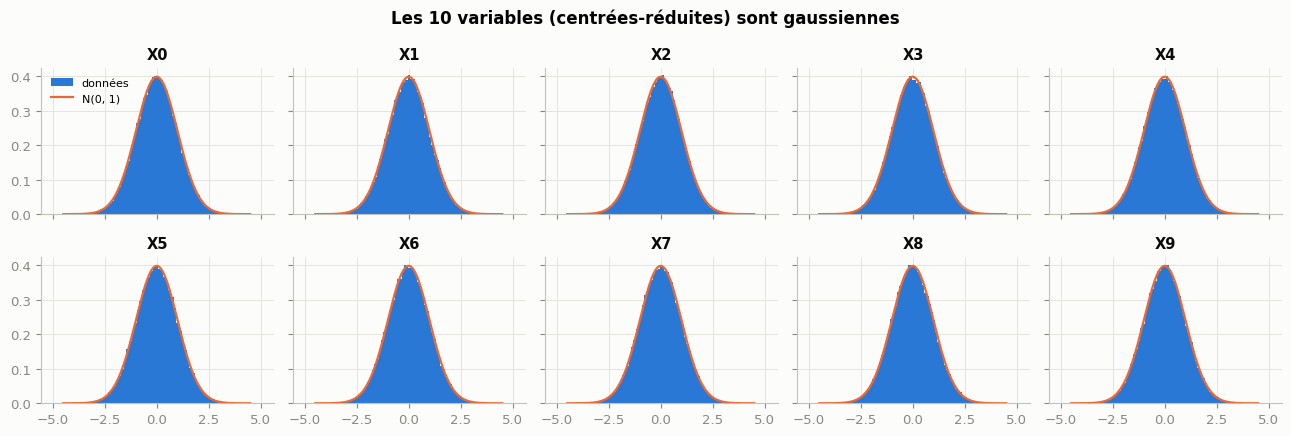

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(13, 4.4), sharex=True, sharey=True)
grid = np.linspace(-4.5, 4.5, 300)
for ax, c in zip(axes.flat, features):
    xs = (df[c] - df[c].mean()) / df[c].std()
    ax.hist(xs, bins=80, density=True, color=BLUE, label="données")
    ax.plot(grid, stats.norm.pdf(grid), color=ORANGE, lw=1.6, label="N(0, 1)")
    ax.set_title(c)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Les 10 variables (centrées-réduites) sont gaussiennes")
fig.tight_layout()

Valeurs exactement égales au min : 5, au max : 2


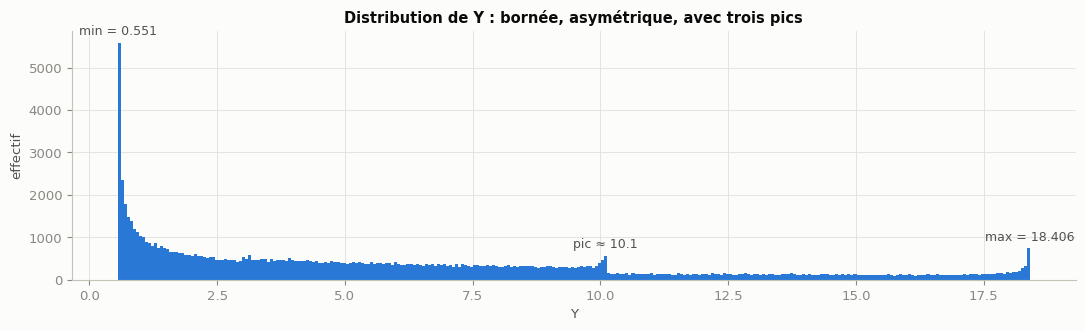

In [4]:
counts, edges = np.histogram(y, bins=300)
centers = (edges[:-1] + edges[1:]) / 2
mid_peak = centers[(centers > 9) & (centers < 11)][np.argmax(counts[(centers > 9) & (centers < 11)])]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.hist(y, bins=edges, color=BLUE)
for v, txt in [(y.min(), f"min = {y.min():.3f}"), (mid_peak, f"pic ≈ {mid_peak:.1f}"), (y.max(), f"max = {y.max():.3f}")]:
    ax.annotate(txt, (v, counts[np.searchsorted(edges, v, side="right") - 1 if v < y.max() else -1]),
                xytext=(0, 6), textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set(xlabel="Y", ylabel="effectif", title="Distribution de Y : bornée, asymétrique, avec trois pics")
fig.tight_layout()

print(f"Valeurs exactement égales au min : {(y == y.min()).sum()}, au max : {(y == y.max()).sum()}")

**Observations**
- Les $X_i$ sont gaussiennes : asymétrie et excès de kurtosis sont ≈ 0.
- Y n'est pas gaussienne. Elle est bornée dans $[0.551, 18.406]$ et présente **trois pics** : au minimum, vers 10.1 et au maximum.
- **Ce n'est pas un écrêtage.** Un *clipping* empilerait des milliers de points exactement sur la borne. On n'en trouve que 5 au minimum et 2 au maximum, des ex-aequo dus à l'arrondi à 6 décimales. Les bornes et les pics doivent donc venir de la forme de la relation $X \to Y$ : on y revient en section 5.

## 2. Inter-corrélations

R² d'une régression linéaire Y ~ X : 0.263


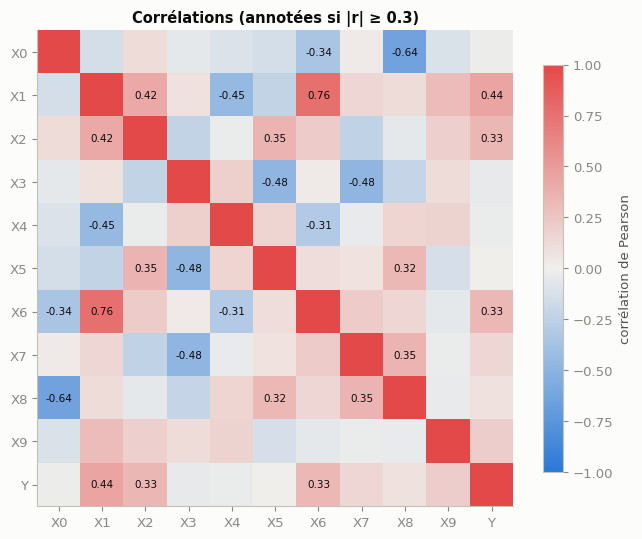

In [5]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6.6, 5.6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(11), corr.columns); ax.set_yticks(range(11), corr.columns)
ax.grid(False)
for i in range(11):
    for j in range(11):
        if i != j and abs(corr.iloc[i, j]) >= 0.3:  # on n'annote que les liens notables
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="corrélation de Pearson")
ax.set_title("Corrélations (annotées si |r| ≥ 0.3)")
fig.tight_layout()

lin = LinearRegression().fit(X, y)
print(f"R² d'une régression linéaire Y ~ X : {r2_score(y, lin.predict(X)):.3f}")

Part de variance expliquée : [0.242 0.21  0.164 0.152 0.099 0.064 0.035 0.026 0.009 0.   ]


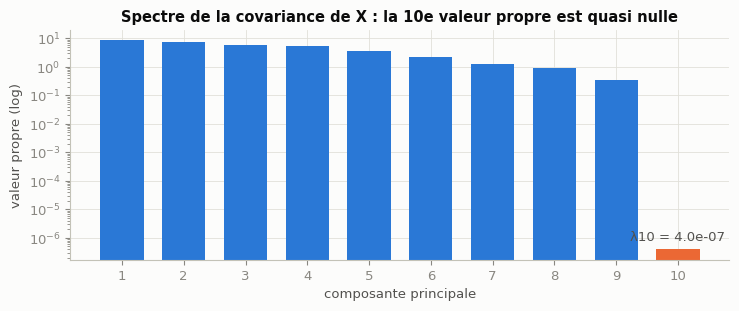

In [6]:
mean, eigvals, eigvecs, W = whitening_matrix(X)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(range(1, 11), eigvals, color=[BLUE] * 9 + [ORANGE], width=0.7)
ax.set_yscale("log")
ax.set(xticks=range(1, 11), xlabel="composante principale", ylabel="valeur propre (log)",
       title="Spectre de la covariance de X : la 10e valeur propre est quasi nulle")
ax.annotate(f"λ10 = {eigvals[-1]:.1e}", (10, eigvals[-1]), xytext=(0, 6), textcoords="offset points",
            ha="center", color=INK2)
fig.tight_layout()
print("Part de variance expliquée :", (eigvals / eigvals.sum()).round(3))

In [7]:
# La 10e direction propre définit une contrainte linéaire exacte entre les variables
v = eigvecs[:, -1]
print(f"Écart-type de (X - μ)·v le long de cette direction : {((X - mean) @ v).std():.1e}  (vs ≈ 2 pour chaque Xi)")

lr9 = LinearRegression().fit(X[:, :9], X[:, 9])
terms = " ".join(f"{c:+.3f}·X{i}" for i, c in enumerate(lr9.coef_))
print(f"\nX9 ≈ {lr9.intercept_:.3f} {terms}")
print(f"R² = {r2_score(X[:, 9], lr9.predict(X[:, :9])):.8f}")

Écart-type de (X - μ)·v le long de cette direction : 6.3e-04  (vs ≈ 2 pour chaque Xi)

X9 ≈ 3.987 -0.702·X0 +2.599·X1 -0.945·X2 -0.088·X3 +0.559·X4 +1.083·X5 -1.968·X6 +0.078·X7 -1.534·X8
R² = 0.99999686


**Découverte n°1 : X n'a que 9 degrés de liberté.**

Les corrélations deux à deux sont modérées (|r| ≤ 0.77), ce qui avait fait conclure à des variables « peu corrélées ». Le spectre montre pourtant une **colinéarité parfaite**. On diagonalise la covariance :

$$\Sigma = V \Lambda V^\top, \qquad \lambda_j = v_j^\top \Sigma\, v_j = \operatorname{Var}\big(v_j^\top X\big).$$

$v_1$ maximise $v^\top \Sigma v$ sous $\|v\|=1$ (quotient de Rayleigh, lagrangien $\Rightarrow \Sigma v = \lambda v$). Chaque $\lambda_j$ est donc la variance du nuage le long de son axe $v_j$. Ici $\lambda_{10} \approx 4\times10^{-7}$, d'où :

$$\operatorname{Var}\big(v_{10}^\top X\big) \approx 0 \;\Longrightarrow\; v_{10}^\top (X-\mu) \approx 0 \quad \text{(contrainte linéaire exacte, au bruit près)}.$$

X9 s'écrit ainsi comme une combinaison linéaire des 9 autres ($R^2 = 1$ au bruit près, écart-type ≈ 6e-4).

Conséquences :
- Une des 10 variables est redondante : l'information tient en 9 dimensions.
- Les coefficients d'un modèle linéaire en X ne sont **pas identifiables**. Pour tout $\lambda$, $\beta^\top (X-\mu) = (\beta + \lambda v_{10})^\top (X-\mu)$. Comme $\|\beta + \lambda v_{10}\|^2 = \|\beta\|^2 + 2\lambda\,\beta^\top v_{10} + \lambda^2$, le représentant de **norme minimale** est l'unique $\beta \perp v_{10}$. C'est celui qu'on rapportera.
- Les corrélations deux à deux ne suffisent pas : il faut regarder la **structure jointe**, c'est-à-dire le spectre.

## 3. Base indépendante : blanchiment

On écarte la direction de variance nulle et on blanchit :

$$Z = \Lambda_k^{-1/2} V_k^\top (X-\mu) \in \mathbb{R}^9, \qquad \operatorname{Cov}(Z) = \Lambda_k^{-1/2} V_k^\top \Sigma V_k \Lambda_k^{-1/2} = \Lambda_k^{-1/2}\Lambda_k\Lambda_k^{-1/2} = I_9,$$

où $V_k, \Lambda_k$ ne gardent que les $k=9$ valeurs propres non nulles. Sur le support des données, la transformation inverse est $X - \mu = V_k \Lambda_k^{1/2} Z$.

Les données sont gaussiennes, donc des composantes **décorrélées sont indépendantes**, car la densité se factorise :

$$p_Z(z) = (2\pi)^{-9/2}\, e^{-\|z\|^2/2} = \prod_{j=1}^{9} \varphi(z_j).$$

In [8]:
Z = (X - mean) @ W
print(f"Dimension de la base blanchie : {Z.shape[1]}")
print(f"max |Cov(Z) - I| = {np.abs(np.cov(Z, rowvar=False) - np.eye(Z.shape[1])).max():.1e}")
print("Excès de kurtosis des composantes :", stats.kurtosis(Z).round(3))

Dimension de la base blanchie : 9
max |Cov(Z) - I| = 7.1e-15
Excès de kurtosis des composantes : [-0.008 -0.03   0.031 -0.023 -0.005 -0.011 -0.005  0.035  0.008]


**Point clé : la base indépendante n'est pas unique.** Pour toute rotation $R$ ($R^\top R = I$, $|\det R| = 1$), par changement de variable :

$$p_{R^\top Z}(z) = p_Z(Rz)\,|\det R| = (2\pi)^{-9/2} e^{-\|Rz\|^2/2} = p_Z(z), \qquad \text{car } \|Rz\| = \|z\|.$$

$R^\top Z$ a donc exactement la même loi que $Z$ : ses composantes sont tout aussi indépendantes.

- La **PCA** choisit une base parmi d'autres, celle qui ordonne les variances. Rien ne l'oblige à être pertinente pour Y.
- L'**ICA** ne peut pas lever l'ambiguïté : elle s'appuie sur la non-gaussianité (théorème de Darmois-Skitovich : identifiable seulement avec au plus une source gaussienne), et ici les kurtosis sont nulles. Un essai de FastICA ne converge d'ailleurs pas.

On le voit ci-dessous : dans la base PCA, Y n'a de lien net avec aucun axe. Cela explique la conclusion de la première analyse, « la PCA ne permet pas d'expliquer la variance simplement ».

Puisque X seul ne fixe pas la rotation, **c'est Y qui doit la choisir**.

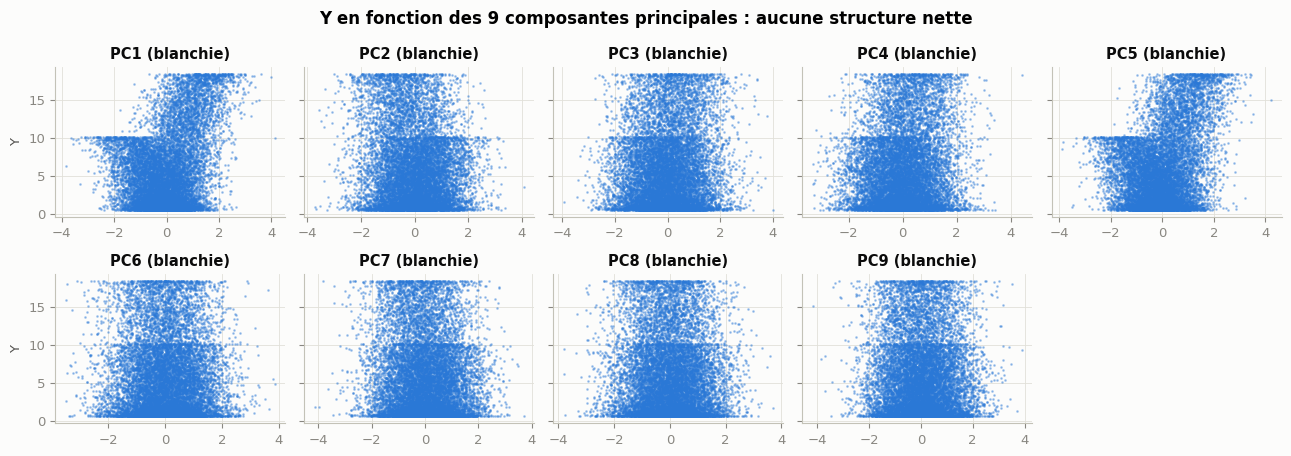

In [9]:
idx = rng.choice(len(y), 12000, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(13, 4.6), sharey=True)
for i, ax in enumerate(axes.flat):
    if i >= Z.shape[1]:
        ax.axis("off"); continue
    ax.scatter(Z[idx, i], y[idx], s=1, color=BLUE, alpha=0.35, rasterized=True)
    ax.set_title(f"PC{i + 1} (blanchie)")
axes[0, 0].set_ylabel("Y"); axes[1, 0].set_ylabel("Y")
fig.suptitle("Y en fonction des 9 composantes principales : aucune structure nette")
fig.tight_layout()

## 4. Rotation supervisée : quelle direction de la base blanchie porte Y ?

À partir d'ici, on ne travaille que sur le jeu d'**apprentissage** (70 %). La validation (15 %) sert aux choix d'hyperparamètres et le test (15 %) n'est utilisé qu'à la fin.

**Modèle à indice unique.** On teste l'hypothèse $Y = f(t, \varepsilon)$ avec $t = u^\top Z$, $\|u\| = 1$ et un bruit $\varepsilon$ indépendant de $Z$. Par construction, $t \sim \mathcal{N}(0,1)$.

**Propriété clé.** $(Z, t)$ est gaussien et $\operatorname{Cov}(Z - u\,t,\; t) = u - u = 0$, donc $Z - u\,t$ est indépendant de $t$, puis de $(t, \varepsilon)$ et donc de $Y$. On en déduit :

$$\mathbb{E}[Z \mid Y] = u\,\mathbb{E}[t \mid Y] + \underbrace{\mathbb{E}[Z - u\,t]}_{=\,0} = u\,\mathbb{E}[t \mid Y].$$

Les moyennes conditionnelles de $Z$ sont toutes **alignées sur $u$**. Leur covariance est de rang 1, et la loi de la variance totale (avec $\operatorname{Var}(t) = 1$) donne sa valeur propre :

$$M = \operatorname{Cov}\big(\mathbb{E}[Z \mid Y]\big) = u u^\top \operatorname{Var}\big(\mathbb{E}[t \mid Y]\big), \qquad \lambda_1 = \operatorname{Var}\big(\mathbb{E}[t \mid Y]\big) = 1 - \mathbb{E}\big[\operatorname{Var}(t \mid Y)\big].$$

**Sliced Inverse Regression (SIR, Li 1991).** On estime $M$ en découpant Y en $H$ tranches de même effectif, de poids $p_h$ et de moyenne $m_h$ des $z_i$ :

$$\hat M = \sum_{h=1}^{H} p_h\, m_h m_h^\top, \qquad \hat u = \arg\max_{\|u\|=1} u^\top \hat M u \;\; (\text{vecteur propre principal}).$$

Si Y dépend de $d$ directions, $\mathbb{E}[Z \mid Y]$ vit dans un sous-espace de dimension $d$ et $M$ est de rang $\le d$. **Le nombre de valeurs propres non nulles indique combien de directions comptent pour Y.**

apprentissage 70000 · validation 15000 · test 15000


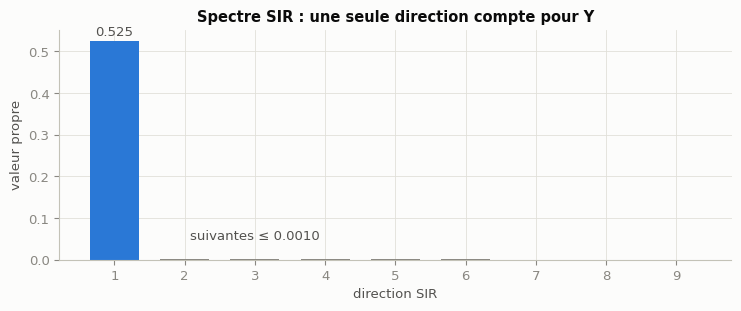

In [10]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)
print(f"apprentissage {len(y_train)} · validation {len(y_val)} · test {len(y_test)}")

mean_tr, _, _, W_tr = whitening_matrix(X_train)
Z_train = (X_train - mean_tr) @ W_tr
sir_vals, sir_dirs = sliced_inverse_regression(Z_train, y_train, n_slices=50)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(range(1, len(sir_vals) + 1), sir_vals, color=[BLUE] + [MUTED] * (len(sir_vals) - 1), width=0.7)
ax.set(xticks=range(1, len(sir_vals) + 1), xlabel="direction SIR", ylabel="valeur propre",
       title="Spectre SIR : une seule direction compte pour Y")
ax.annotate(f"{sir_vals[0]:.3f}", (1, sir_vals[0]), xytext=(0, 4), textcoords="offset points", ha="center", color=INK2)
ax.annotate(f"suivantes ≤ {sir_vals[1]:.4f}", (2, sir_vals[1]), xytext=(4, 14), textcoords="offset points", color=INK2)
fig.tight_layout()

**Découverte n°2 : Y ne dépend que d'une seule direction.** La première valeur propre SIR vaut 0.525 et les suivantes sont inférieures à $10^{-3}$.

Pourquoi $\lambda_1 < 1$ ? D'après la formule ci-dessus, $1 - \lambda_1 = \mathbb{E}[\operatorname{Var}(t \mid Y)] = 0.475$. $f$ n'est pas injective : une même valeur de $y$ a 2 à 4 antécédents $t$, que la moyenne de tranche mélange. Avec une $f$ monotone, on aurait $\lambda_1 \approx 1$.

On construit ensuite une rotation $R = [u, r_2, \dots, r_9]$ dont la **première colonne est $u$**, par décomposition QR (Gram-Schmidt) de $[u, e_1, \dots, e_9]$.

**Affinage par Gauss-Newton.** On résout $\min_{u, f} \sum_i \big(y_i - f(u^\top z_i)\big)^2$ en alternant deux étapes. À $u$ fixé, on ajuste la spline $f$. À $f$ fixée, on linéarise au premier ordre en $\delta$ :

$$f\big((u+\delta)^\top z_i\big) \approx f(t_i) + f'(t_i)\, z_i^\top \delta \;\Longrightarrow\; (J^\top J)\,\hat\delta = J^\top r, \qquad J = \operatorname{diag}\big(f'(t)\big)\, Z, \quad r = y - f(t),$$

puis $u \leftarrow (u + \hat\delta)/\|u + \hat\delta\|$. C'est un pas de Newton dans lequel le hessien est approché par $J^\top J$, en négligeant le terme $\sum_i r_i \nabla^2 f$, petit quand les résidus le sont.

**Pourquoi un petit angle coûte cher.** Si $\hat u$ fait un angle $\theta$ avec $u$, alors $\hat t - t \approx \theta\, \eta^\top Z \sim \mathcal{N}(0, \theta^2)$ avec $\eta \perp u$ unitaire, d'où :

$$\mathrm{MSE}(\hat u) \approx \theta^2\, \mathbb{E}\big[f'(t)^2\big].$$

Tout cela est encapsulé dans `RotatedSingleIndexRegressor`.

Angle entre la direction SIR initiale et la direction affinée : 0.52°
MSE (apprentissage) au fil des itérations : ['5.27e-03', '2.52e-04', '2.52e-04', '2.52e-04', '2.52e-04', '1.45e-06', '1.40e-06', '1.40e-06', '1.40e-06', '1.40e-06']
θ²·E[f'(t)²] = 5.03e-03  vs  MSE observée avec la direction SIR seule : 5.27e-03


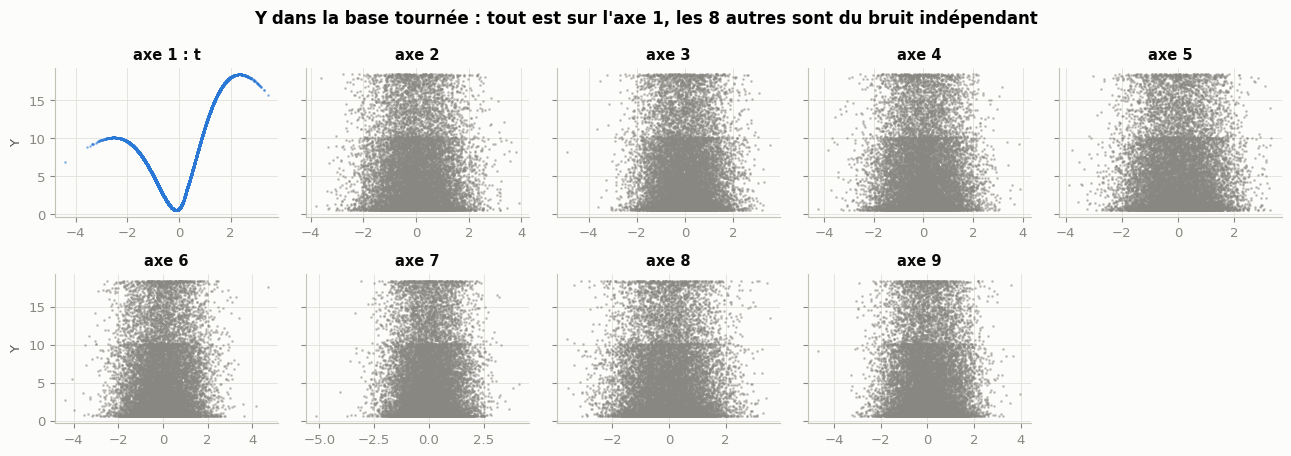

In [11]:
model = RotatedSingleIndexRegressor(n_knots=40, kinks="auto").fit(X_train, y_train)

u_sir = sir_dirs[:, 0] * np.sign(sir_dirs[:, 0] @ model.direction_)
angle = np.degrees(np.arccos(np.clip(u_sir @ model.direction_, -1, 1)))
print(f"Angle entre la direction SIR initiale et la direction affinée : {angle:.2f}°")
print("MSE (apprentissage) au fil des itérations :", [f"{m:.2e}" for m in model.refine_history_])
Ef2 = np.mean(model.spline_.derivative(model.index(X_train)) ** 2)
print(f"θ²·E[f'(t)²] = {np.radians(angle) ** 2 * Ef2:.2e}  vs  MSE observée avec la direction SIR seule : {model.refine_history_[0]:.2e}")

R_train = model.transform(X_train)  # 9 composantes indépendantes, axe 1 = axe informatif
sub_tr = rng.choice(len(y_train), 12000, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(13, 4.6), sharey=True)
for i, ax in enumerate(axes.flat):
    if i >= R_train.shape[1]:
        ax.axis("off"); continue
    ax.scatter(R_train[sub_tr, i], y_train[sub_tr], s=1,
               color=BLUE if i == 0 else MUTED, alpha=0.4, rasterized=True)
    ax.set_title("axe 1 : t" if i == 0 else f"axe {i + 1}")
axes[0, 0].set_ylabel("Y"); axes[1, 0].set_ylabel("Y")
fig.suptitle("Y dans la base tournée : tout est sur l'axe 1, les 8 autres sont du bruit indépendant")
fig.tight_layout()

t = β·(X − μ) avec β = {'X0': 0.0785, 'X1': 0.281, 'X2': 0.2534, 'X3': 0.0052, 'X4': 0.1279, 'X5': -0.0639, 'X6': 0.116, 'X7': 0.1114, 'X8': 0.0904, 'X9': 0.0791}
|cos(direction des moyennes de tranches, Σβ)| = 1.0000   |cos(…, β)| = 0.8812


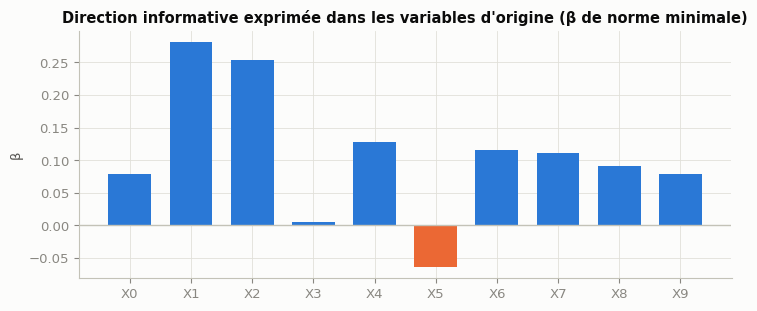

In [12]:
coef = pd.Series(model.coef_, index=features)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(features, coef, color=[BLUE if c > 0 else ORANGE for c in coef], width=0.7)
ax.axhline(0, color=AXIS, lw=1)
ax.set(ylabel="β", title="Direction informative exprimée dans les variables d'origine (β de norme minimale)")
fig.tight_layout()
print("t = β·(X − μ) avec β =", coef.round(4).to_dict())

# Dans l'espace de X, les moyennes conditionnelles s'alignent sur Σβ, pas sur β
edges_y = np.quantile(y_train, np.linspace(0, 1, 51))
sid = np.clip(np.searchsorted(edges_y, y_train, side="right") - 1, 0, 49)
slice_means = np.array([(X_train[sid == h] - model.mean_).mean(axis=0) for h in range(50)])
d_cm = np.linalg.svd(slice_means, full_matrices=False)[2][0]
s_beta = np.cov(X_train, rowvar=False) @ model.coef_
cos = lambda a, b: abs(a @ b) / np.linalg.norm(a) / np.linalg.norm(b)
print(f"|cos(direction des moyennes de tranches, Σβ)| = {cos(d_cm, s_beta):.4f}   |cos(…, β)| = {cos(d_cm, model.coef_):.4f}")

Dans les variables d'origine, la direction informative mélange presque toutes les variables. Les poids principaux vont à X1 et X2, puis à X4, X6, X7, X8 et X9. Aucune variable seule ne l'approche, ce qui explique les corrélations linéaires faibles entre Y et chaque $X_i$.

En combinant blanchiment et rotation : $t = u^\top \Lambda_k^{-1/2} V_k^\top (X - \mu) = \beta^\top (X-\mu)$ avec $\beta = V_k \Lambda_k^{-1/2} u$. Les colonnes de $V_k$ sont orthogonales à $v_{10}$, donc $\beta \perp v_{10}$ : c'est automatiquement le représentant de norme minimale de la section 2.

**Pourquoi blanchir avant SIR ?** Avec $X - \mu = V_k \Lambda_k^{1/2} Z$ :

$$\mathbb{E}[X - \mu \mid Y] = V_k \Lambda_k^{1/2} u\;\mathbb{E}[t \mid Y] = \Sigma\beta\;\mathbb{E}[t \mid Y], \qquad \text{car } \Sigma\beta = V_k\Lambda_k V_k^\top V_k \Lambda_k^{-1/2} u = V_k \Lambda_k^{1/2} u.$$

Dans l'espace d'origine, les moyennes conditionnelles s'alignent sur $\Sigma\beta$ et **non sur $\beta$** (vérifié ci-dessus : cos = 1.000 contre 0.88). Sans blanchiment, il faudrait résoudre le problème aux valeurs propres généralisé $\operatorname{Cov}(\mathbb{E}[X \mid Y])\,\beta = \lambda\, \Sigma\, \beta$.

## 5. La forme de $f$ : pics, bornes et coude

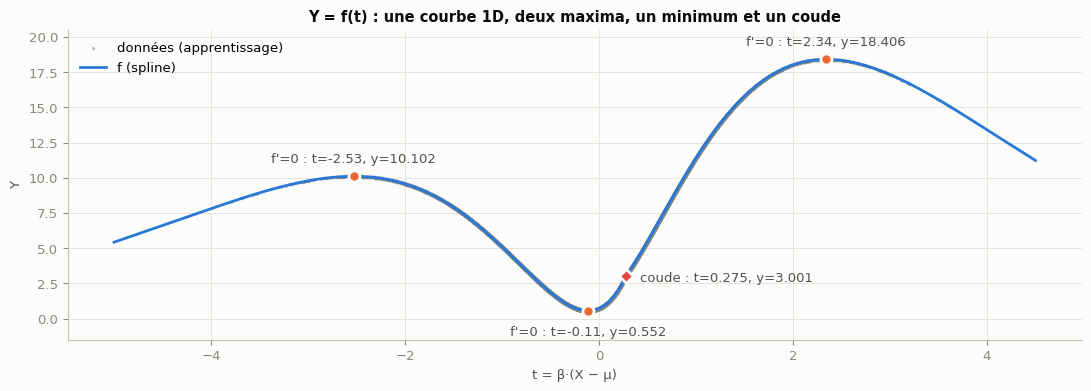

In [13]:
t_train = model.index(X_train)
tg = np.linspace(-5, 4.5, 20001)
fg, dg = model.spline_(tg), model.spline_.derivative(tg)
crit = np.where(np.diff(np.sign(dg)) != 0)[0]
extrema = [(tg[i], fg[i]) for i in crit]

sub = rng.choice(len(y_train), 15000, replace=False)
fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(t_train[sub], y_train[sub], s=2, color=MUTED, alpha=0.4, label="données (apprentissage)", rasterized=True)
ax.plot(tg, fg, color=BLUE, label="f (spline)")
for tc, fc in extrema:
    ax.plot(tc, fc, "o", ms=8, color=ORANGE, mec=SURFACE, mew=2)
    ax.annotate(f"f'=0 : t={tc:.2f}, y={fc:.3f}", (tc, fc), xytext=(0, 10 if fc > 5 else -18),
                textcoords="offset points", ha="center", color=INK2)
for k in model.kinks_:
    ax.plot(k, model.spline_(k), "D", ms=7, color=RED, mec=SURFACE, mew=2)
    ax.annotate(f"coude : t={k:.3f}, y={model.spline_(k):.3f}", (k, model.spline_(k)), xytext=(10, -4),
                textcoords="offset points", color=INK2)
ax.set(xlabel="t = β·(X − μ)", ylabel="Y", ylim=(-1.5, 20.5),
       title="Y = f(t) : une courbe 1D, deux maxima, un minimum et un coude")
ax.legend(loc="upper left")
fig.tight_layout()

**Les trois pics de l'histogramme sont les extrema de $f$.** On découpe $\mathbb{R}$ en intervalles où $f$ est strictement monotone, et on note $t_k(y)$ l'antécédent de $y$ sur chacun. Alors $F_Y(y) = \sum_k \pm\,\Phi\big(t_k(y)\big) + \text{cste}$. En dérivant, avec $t_k'(y) = 1/f'(t_k)$ :

$$p_Y(y) = \sum_{t_k:\, f(t_k)=y} \frac{\varphi(t_k)}{|f'(t_k)|}.$$

Cette densité **diverge là où $f'(t_k)=0$** : au minimum $f \approx 0.551$, au maximum local $f \approx 10.10$ et au maximum global $f \approx 18.41$. Près d'un extremum $t^*$, $f(t) \approx y^* + \tfrac12 f''(t^*)(t-t^*)^2$. Les deux antécédents vérifient alors $|f'(t_\pm)| = \sqrt{2|f''(t^*)|\,|y-y^*|}$, d'où :

$$p_Y(y) \approx \frac{2\,\varphi(t^*)}{\sqrt{2\,|f''(t^*)|\,|y-y^*|}}.$$

C'est une singularité intégrable en $|y-y^*|^{-1/2}$ : un pic fin mais de masse finie. Les bornes de Y sont simplement les extrema de $f$. La courbe orange ci-dessous est la densité prédite par le modèle, sans aucun ajustement sur l'histogramme.

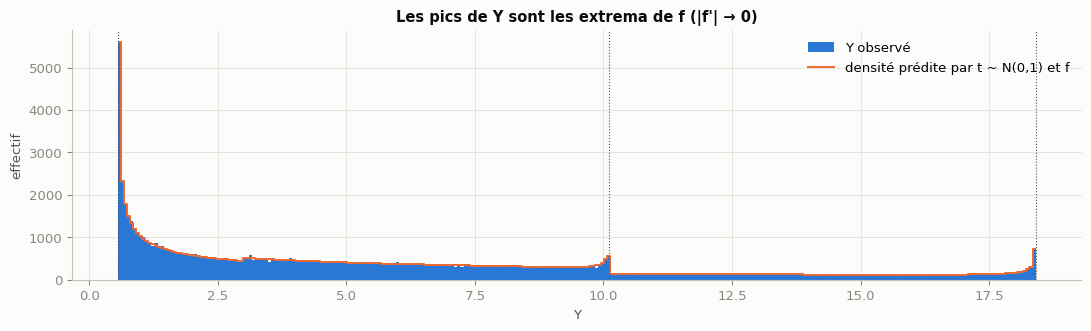

In [14]:
tt = np.linspace(-6, 6, 2_000_001)
w = stats.norm.pdf(tt) * (tt[1] - tt[0]) * len(y)
pred_counts, _ = np.histogram(model.spline_(tt), bins=edges, weights=w)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.hist(y, bins=edges, color=BLUE, label="Y observé")
ax.step(centers, pred_counts, where="mid", color=ORANGE, lw=1.4, label="densité prédite par t ~ N(0,1) et f")
for _, fc in extrema:
    ax.axvline(fc, color=INK2, lw=0.8, ls=":")
ax.set(xlabel="Y", ylabel="effectif", title="Les pics de Y sont les extrema de f (|f'| → 0)")
ax.legend()
fig.tight_layout()

**Découverte n°3 : $f$ a un coude.** Une première version avec une spline lisse laissait des résidus structurés autour de $t \approx 0.27$ ($y \approx 3$).

**Test de rupture de pente.** En chaque point $c$, on ajuste par moindres carrés $y \approx a + b\,(s-c) + q\,(s-c)^2$ sur $[c-h, c)$, puis sur $(c, c+h]$, avec $h = 0.03$. Les coefficients $\hat b_-$ et $\hat b_+$ estiment les pentes à gauche et à droite de $c$. On standardise leur écart de façon robuste :

$$\Delta(c) = \hat b_+(c) - \hat b_-(c), \qquad z(c) = \frac{\Delta(c) - \operatorname{med}(\Delta)}{1.4826\,\operatorname{MAD}(\Delta)}, \qquad 1.4826 = \frac{1}{\Phi^{-1}(3/4)}.$$

La constante rend la MAD égale à $\sigma$ pour une loi normale, car $\operatorname{med}|X - \mu| = \sigma\,\Phi^{-1}(3/4)$.

Un seul point ressort, très nettement : $f$ y est **continue mais sa dérivée saute**. Sur la branche gauche, $f$ repasse aussi par $y=3$ sans aucun coude : la rupture est donc définie sur $t$, pas sur $y$.

**Modélisation par un nœud triple.** Dans la base des puissances tronquées, une spline cubique s'écrit $f(t) = \sum_{j=0}^{3} a_j t^j + \sum_k b_k (t-\kappa_k)_+^3$. Chaque terme est $C^2$ en $\kappa_k$, donc la spline aussi. Un nœud de multiplicité $m$ ajoute les termes $(t-\kappa)_+^{3}, \dots, (t-\kappa)_+^{4-m}$, ce qui donne une régularité $C^{3-m}$. Avec un **nœud triple**, le terme $b\,(t-\kappa)_+$ apparaît et autorise un saut de pente $f'(\kappa^+) - f'(\kappa^-) = b$. Sa position $\kappa$ est optimisée par une recherche 1D sur l'erreur d'ajustement.

**Trace du coude dans la loi de Y.** D'après la formule de $p_Y$, la densité saute en $y = f(\kappa)$ de $\varphi(\kappa)\big(1/f'(\kappa^+) - 1/f'(\kappa^-)\big)$. La cellule suivante compare ce saut prédit à l'histogramme.

Coude en t = 0.2754 ; f = 3.0006 ; pente à gauche = 14.63, à droite = 9.77
Saut de densité prédit en y = 3 : φ(κ)·(1/f'₊ − 1/f'₋) = +0.0130
  densité empirique de Y sur [2.8, 2.95) : 0.0753
  densité empirique de Y sur [3.05, 3.2) : 0.0882


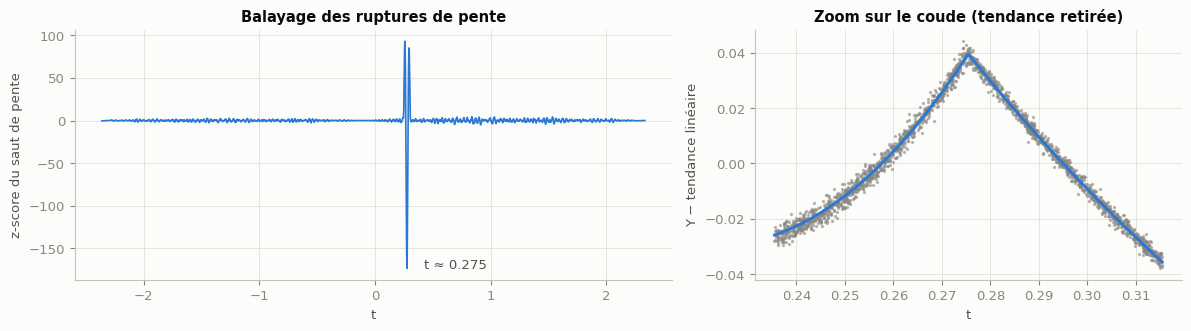

In [15]:
c, jumps, z = slope_jumps(t_train, y_train)
k = model.kinks_[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].plot(c, z, color=BLUE, lw=1.2)
axes[0].set(xlabel="t", ylabel="z-score du saut de pente", title="Balayage des ruptures de pente")
axes[0].annotate(f"t ≈ {k:.3f}", (c[np.argmin(z)], z.min()), xytext=(12, 0), textcoords="offset points", color=INK2)

win = (t_train > k - 0.04) & (t_train < k + 0.04)
trend = np.polyfit(t_train[win], y_train[win], 1)
tz = np.linspace(k - 0.04, k + 0.04, 400)
axes[1].scatter(t_train[win], y_train[win] - np.polyval(trend, t_train[win]), s=2, color=MUTED, alpha=0.5, rasterized=True)
axes[1].plot(tz, model.spline_(tz) - np.polyval(trend, tz), color=BLUE)
axes[1].set(xlabel="t", ylabel="Y − tendance linéaire", title="Zoom sur le coude (tendance retirée)")
fig.tight_layout()

eps = 1e-7
s_left, s_right = model.spline_.derivative(k - eps), model.spline_.derivative(k + eps)
print(f"Coude en t = {k:.4f} ; f = {model.spline_(k):.4f} ; pente à gauche = {s_left:.2f}, à droite = {s_right:.2f}")
print(f"Saut de densité prédit en y = 3 : φ(κ)·(1/f'₊ − 1/f'₋) = {stats.norm.pdf(k) * (1 / s_right - 1 / s_left):+.4f}")
for a, b in [(2.80, 2.95), (3.05, 3.20)]:
    print(f"  densité empirique de Y sur [{a}, {b}) : {((y >= a) & (y < b)).mean() / (b - a):.4f}")

**Peut-on trouver une forme analytique de $f$ ?** On a testé quelques familles simples à 5 ou 6 paramètres. Aucune ne s'approche de la spline : leurs MSE sont 5 ordres de grandeur au-dessus. On garde donc une représentation **non paramétrique** de $f$, une spline cubique à 40 nœuds plus le coude, et la question de la formule exacte reste ouverte.

In [16]:
forms = {
    "a + b·s²/(1+c·s⁴) + d·s":        (lambda t, a, b, c, d, e: a + b * (t - c) ** 2 / (1 + d * (t - c) ** 4) + e * (t - c), [0.5, 3, 0, 0.03, 0.5]),
    "a + b·s²·exp(-c·s² + d·s)":      (lambda t, a, b, c, d, e: a + b * (t - c) ** 2 * np.exp(-d * (t - c) ** 2 + e * (t - c)), [0.5, 8, 0, 0.15, 0.1]),
    "a + exp(-c·t²)·(cubique en t)":  (lambda t, a, b0, b1, b2, b3, d: a + np.exp(-d * t ** 2) * (b0 + b1 * t + b2 * t ** 2 + b3 * t ** 3), [0.5, 0, 0, 8, 1, 0.15]),
    "a + b·sin(c·t + d) + e·t + g·t²":(lambda t, a, b, c, d, e, g: a + b * np.sin(c * t + d) + e * t + g * t ** 2, [8, 8, 1.2, 0, 1, 0]),
}
rows = []
for name, (fn, p0) in forms.items():
    p, _ = curve_fit(fn, t_train, y_train, p0=p0, maxfev=20000)
    rows.append((name, np.mean((y_train - fn(t_train, *p)) ** 2)))
rows.append(("spline cubique 40 nœuds + coude", np.mean((y_train - model.predict(X_train)) ** 2)))
pd.DataFrame(rows, columns=["forme de f(t)", "MSE apprentissage"]).style.format({"MSE apprentissage": "{:.2e}"})

,forme de f(t),MSE apprentissage
0,a + b·s²/(1+c·s⁴) + d·s,4.19e-01
1,a + b·s²·exp(-c·s² + d·s),2.77e-01
2,a + exp(-c·t²)·(cubique en t),1.68e-01
3,a + b·sin(c·t + d) + e·t + g·t²,2.43e-01
4,spline cubique 40 nœuds + coude,1.40e-06


## 6. Modèle final et validation

Récapitulatif du modèle `RotatedSingleIndexRegressor` :
1. **Blanchiment** de X : centrage, PCA, suppression de la direction de variance nulle, mise à l'échelle → 9 composantes indépendantes.
2. **Rotation supervisée** : direction initiale par SIR, affinée par Gauss-Newton.
3. **Coude** : détection par balayage des sauts de pente, puis position optimisée.
4. **$f$** : spline cubique de régression dans la base des B-splines. Les nœuds sont uniformes entre les quantiles 0.05 % et 99.95 % de $t$, pour garder de la résolution dans les queues, avec un nœud triple au coude :

$$f(t) = \sum_{j=1}^{K+4} c_j B_j(t), \qquad \hat c = \arg\min_c \|y - Bc\|^2 = (B^\top B)^{-1} B^\top y.$$

Ici $K$ compte les nœuds intérieurs avec leur multiplicité. $B_{ij} = B_j(t_i)$ a au plus 4 coefficients non nuls par ligne : le système est bande et se résout en $O(n)$. Avec 40 nœuds plus le coude, $K = 42$, soit 46 coefficients.

Hors du domaine d'apprentissage $[a, b]$, on **prolonge linéairement** : $f(t) = f(b) + f'(b)(t - b)$ pour $t > b$, et symétriquement pour $t < a$. Un prolongement constant faisait exploser l'erreur sur les rares points extrêmes du jeu de test.

**Choix du nombre de nœuds** sur le jeu de validation, avec et sans coude :

coude,avec coude,sans coude
nœuds,,
10,8.81e-05,4.64e-02
15,1.14e-05,1.84e-03
20,3.28e-06,1.68e-03
30,1.46e-06,1.96e-04
40,1.45e-06,2.63e-04
60,1.44e-06,6.72e-05
80,1.45e-06,2.28e-05
120,1.45e-06,4.70e-06
160,1.45e-06,2.50e-06


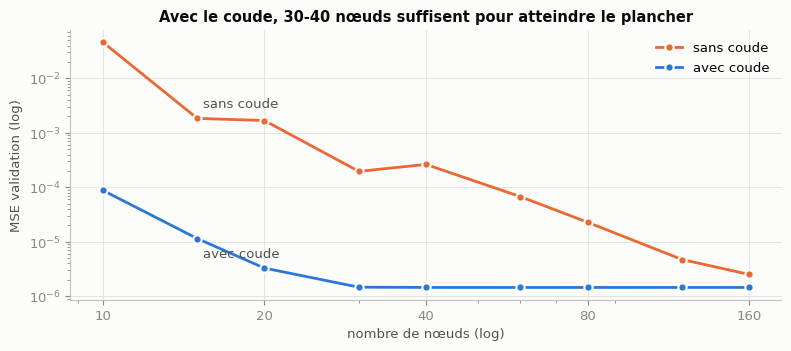

In [17]:
rows = []
for kinks in [None, "auto"]:
    for n in [10, 15, 20, 30, 40, 60, 80, 120, 160]:
        m = RotatedSingleIndexRegressor(n_knots=n, kinks=kinks).fit(X_train, y_train)
        rows.append({"coude": "avec coude" if kinks else "sans coude", "nœuds": n,
                     "paramètres": m.n_parameters_, "MSE validation": mean_squared_error(y_val, m.predict(X_val))})
knots_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
for label, color, dy in [("sans coude", ORANGE, 8), ("avec coude", BLUE, -14)]:
    d = knots_df[knots_df["coude"] == label]
    ax.plot(d["nœuds"], d["MSE validation"], "o-", color=color, ms=6, mec=SURFACE, mew=1.5, label=label)
    ax.annotate(label, (d["nœuds"].iloc[1], d["MSE validation"].iloc[1]), xytext=(4, dy),
                textcoords="offset points", color=INK2)
ax.set_yscale("log"); ax.set_xscale("log")
ax.set(xlabel="nombre de nœuds (log)", ylabel="MSE validation (log)",
       title="Avec le coude, 30-40 nœuds suffisent pour atteindre le plancher")
ax.set_xticks([10, 20, 40, 80, 160], ["10", "20", "40", "80", "160"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend(loc="upper right")
fig.tight_layout()
knots_df.pivot(index="nœuds", columns="coude", values="MSE validation").style.format("{:.2e}")

Sans coude, la spline doit multiplier les nœuds pour approcher la rupture de pente, et n'atteint qu'environ 2.5e-6 avec 160 nœuds. Avec le coude, **30 à 40 nœuds suffisent** pour atteindre environ 1.45e-6. On retient **40 nœuds**, soit 58 paramètres au total.

**Évaluation finale** sur le jeu de test, et validation croisée à 5 plis sur les 100 000 points :

In [18]:
final = RotatedSingleIndexRegressor(n_knots=40, kinks="auto").fit(X_train, y_train)
res = {name: mean_squared_error(yy, final.predict(xx))
       for name, xx, yy in [("apprentissage", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]}
print("MSE :", {k: f"{v:.2e}" for k, v in res.items()})
print(f"R² test = {r2_score(y_test, final.predict(X_test)):.8f}   ·   paramètres = {final.n_parameters_}")

cv = []
for a, b in KFold(5, shuffle=True, random_state=0).split(X):
    cv.append(mean_squared_error(y[b], RotatedSingleIndexRegressor(n_knots=40).fit(X[a], y[a]).predict(X[b])))
print(f"Validation croisée 5 plis : MSE = {np.mean(cv):.3e} ± {np.std(cv):.1e}")

MSE : {'apprentissage': '1.40e-06', 'validation': '1.45e-06', 'test': '1.44e-06'}
R² test = 0.99999994   ·   paramètres = 58


Validation croisée 5 plis : MSE = 1.413e-06 ± 1.7e-08


**Comparaison** sur le même découpage. Les modèles « sur t » ne reçoivent que la coordonnée tournée $t$ (1 variable) au lieu des 10 variables brutes.

,MSE apprentissage,MSE validation,MSE test
modèle,,,
Régression linéaire (X),1.82e+01,1.79e+01,1.80e+01
Polynôme degré 2 (X),5.85e+00,5.94e+00,5.97e+00
Gradient boosting (X brut),1.62e-01,2.49e-01,2.54e-01
Gradient boosting (t seul),5.29e-03,6.92e-03,8.77e-03
"Rotation + spline, sans coude",2.52e-04,2.63e-04,2.60e-04
Rotation + spline + coude,1.40e-06,1.45e-06,1.44e-06


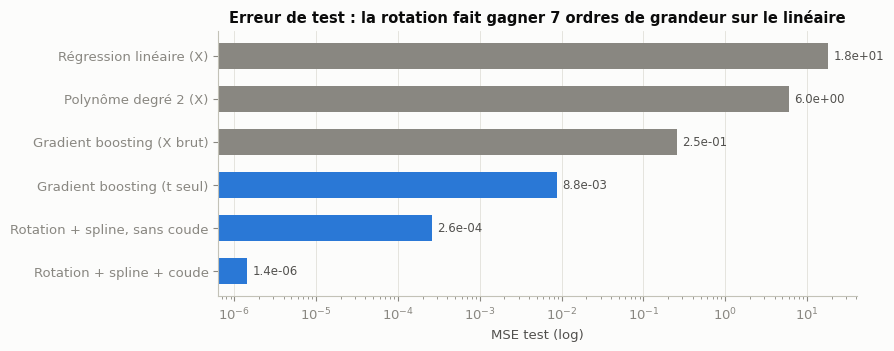

In [19]:
t_tr, t_va, t_te = (final.index(A)[:, None] for A in (X_train, X_val, X_test))
candidates = [
    ("Régression linéaire (X)",          LinearRegression(), False),
    ("Polynôme degré 2 (X)",             make_pipeline(PolynomialFeatures(2), LinearRegression()), False),
    ("Gradient boosting (X brut)",       HistGradientBoostingRegressor(max_iter=500, random_state=0), False),
    ("Gradient boosting (t seul)",       HistGradientBoostingRegressor(max_iter=500, random_state=0), True),
    ("Rotation + spline, sans coude",    RotatedSingleIndexRegressor(n_knots=40, kinks=None), False),
    ("Rotation + spline + coude",        final, False),
]
rows = []
for name, est, on_t in candidates:
    A_tr, A_va, A_te = (t_tr, t_va, t_te) if on_t else (X_train, X_val, X_test)
    if est is not final:
        est.fit(A_tr, y_train)
    rows.append({"modèle": name,
                 "MSE apprentissage": mean_squared_error(y_train, est.predict(A_tr)),
                 "MSE validation": mean_squared_error(y_val, est.predict(A_va)),
                 "MSE test": mean_squared_error(y_test, est.predict(A_te))})
cmp_df = pd.DataFrame(rows).set_index("modèle")

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [BLUE if "Rotation" in n or "t seul" in n else MUTED for n in cmp_df.index]
ax.barh(cmp_df.index[::-1], cmp_df["MSE test"][::-1], color=colors[::-1], height=0.6)
ax.set_xscale("log")
for i, v in enumerate(cmp_df["MSE test"][::-1]):
    ax.annotate(f"{v:.1e}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", color=INK2, fontsize=8.5)
ax.set(xlabel="MSE test (log)", title="Erreur de test : la rotation fait gagner 7 ordres de grandeur sur le linéaire")
ax.grid(axis="y", visible=False)
fig.tight_layout()
cmp_df.style.format("{:.2e}")

Pour mémoire, les résultats de la première approche (README, **autre découpage**, donc indicatifs) :

| Modèle (README) | Paramètres | MSE validation | MSE test |
|---|---:|---:|---:|
| XGBoost | – | 2.1e-2 | 1.6e-1 |
| MLP | 9 729 | 2.5e-5 | 3.1e-5 |
| MLP | 625 | 3.0e-5 | 2.1e-5 |
| **Rotation + spline + coude** | **58** | **1.4e-6** | **1.4e-6** |

Ce qu'on retient :
- **La rotation est la vraie « ingénierie de variables ».** Le même gradient boosting passe de 2.5e-1 sur X brut à environ 1e-2 sur la seule variable $t$.
- Le MLP apprenait implicitement $t$ et $f$. Le modèle explicite fait **environ 15 fois mieux avec environ 10 fois moins de paramètres**. Il est interprétable et s'entraîne en quelques secondes sur CPU.

## 7. Résidus : a-t-on atteint le plancher de bruit ?

**Risque de Bayes.** Pour tout prédicteur $g$, en développant autour de $\mathbb{E}[Y \mid X]$ (le terme croisé est nul) :

$$\mathbb{E}\big[(Y - g(X))^2\big] = \mathbb{E}\big[\operatorname{Var}(Y \mid X)\big] + \mathbb{E}\big[(\mathbb{E}[Y \mid X] - g(X))^2\big] \;\ge\; \mathbb{E}\big[\operatorname{Var}(Y \mid X)\big].$$

**Bruit sur l'indice.** Si $Y = f(t + \varepsilon)$ avec $\varepsilon \sim \mathcal{N}(0, \sigma_t^2)$ indépendant de $X$, un développement de Taylor donne :

$$Y - f(t) = f'(t)\,\varepsilon + \tfrac12 f''(t)\,\varepsilon^2 + O(\varepsilon^3) \;\Longrightarrow\; \operatorname{Var}(Y \mid t) \approx f'(t)^2 \sigma_t^2, \qquad \mathrm{MSE}_{\min} \approx \sigma_t^2\, \mathbb{E}\big[f'(t)^2\big].$$

Le biais $\mathbb{E}[Y \mid t] - f(t) \approx \tfrac12 f''(t)\,\sigma_t^2$ est inférieur à $10^{-6}$ ici : son carré est négligeable. Il reste à vérifier deux prédictions : des résidus proportionnels à $|f'(t)|$, et $\sigma_t$ estimable par l'écart-type de $r_i / f'(t_i)$.

Bruit sur t (|t| < 3) : σ_t = 1.53e-04 ; excès de kurtosis de r/f' = -0.053
Plancher attendu σ_t²·E[f'(t)²] = 1.44e-06  vs  MSE test = 1.44e-06
Corrélation des résidus avec les 8 autres axes : [ 0.004 -0.005  0.001  0.007 -0.     0.012 -0.013  0.002]


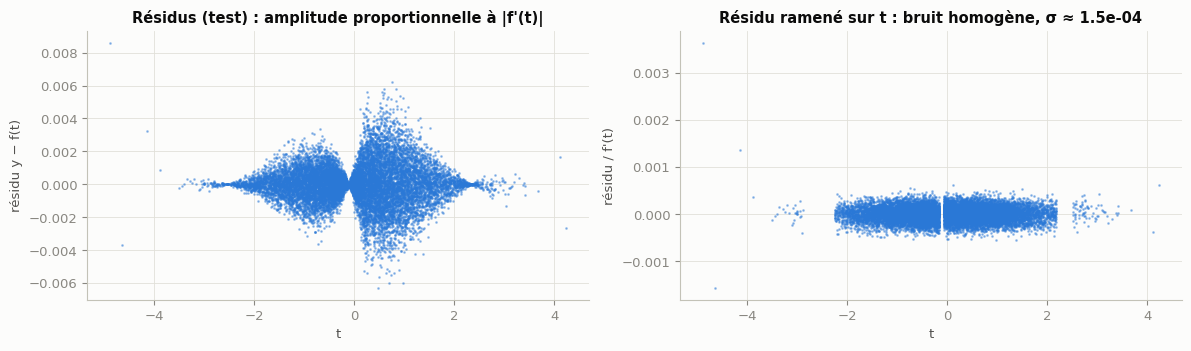

In [20]:
t_test = final.index(X_test)
r_test = y_test - final.predict(X_test)
d_test = final.spline_.derivative(t_test)
steep = np.abs(d_test) > 1  # on normalise là où f' n'est pas trop petite
core = steep & (np.abs(t_test) < 3)  # hors des queues extrêmes (quelques points extrapolés)
sigma_t = (r_test[core] / d_test[core]).std()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].scatter(t_test, r_test, s=1, color=BLUE, alpha=0.4, rasterized=True)
axes[0].set(xlabel="t", ylabel="résidu y − f(t)", title="Résidus (test) : amplitude proportionnelle à |f'(t)|")
axes[1].scatter(t_test[steep], r_test[steep] / d_test[steep], s=1, color=BLUE, alpha=0.4, rasterized=True)
axes[1].set(xlabel="t", ylabel="résidu / f'(t)", title=f"Résidu ramené sur t : bruit homogène, σ ≈ {sigma_t:.1e}")
fig.tight_layout()

floor = sigma_t ** 2 * np.mean(final.spline_.derivative(t_test) ** 2)
print(f"Bruit sur t (|t| < 3) : σ_t = {sigma_t:.2e} ; excès de kurtosis de r/f' = {stats.kurtosis(r_test[core] / d_test[core]):.3f}")
print(f"Plancher attendu σ_t²·E[f'(t)²] = {floor:.2e}  vs  MSE test = {np.mean(r_test ** 2):.2e}")
print("Corrélation des résidus avec les 8 autres axes :", np.round([np.corrcoef(final.transform(X_test)[:, i], r_test)[0, 1] for i in range(1, 9)], 3))

**Découverte n°4 : l'erreur restante est un bruit irréductible sur $t$.**
- L'amplitude des résidus est proportionnelle à $|f'(t)|$. Elle est nulle aux extrema et maximale là où $f$ est raide. Le bruit agit donc sur l'**entrée** $t$ et non sur Y : $y = f(t + \varepsilon)$ avec $\varepsilon \sim \mathcal{N}(0, \sigma_t^2)$ et $\sigma_t \approx 1.5\times10^{-4}$, kurtosis nulle.
- La MSE attendue d'un prédicteur parfait est $\sigma_t^2\,\mathbb{E}[f'(t)^2] \approx 1.4\times10^{-6}$, c'est-à-dire **la MSE obtenue**. Les résidus ne sont plus corrélés à aucun des 8 autres axes.

Avec ces données, aucun modèle ne peut faire significativement mieux.

## 8. Conclusions, choix et questions

**Démarche**
1. Analyse descriptive : X est gaussien et Y bornée avec trois pics. Ce n'est pas un écrêtage.
2. Inter-corrélations, en regardant le **spectre** et pas seulement les corrélations deux à deux : X n'a que 9 degrés de liberté.
3. Blanchiment : 9 composantes indépendantes, mais définies seulement **à une rotation près**, puisque les données sont gaussiennes.
4. Choix de la rotation **avec Y** (SIR puis Gauss-Newton) : un seul axe porte toute l'information.
5. Modèle 1D sur cet axe (spline avec coude), validé sur des jeux séparés et par validation croisée. Il atteint le plancher de bruit.

**Pourquoi ces choix**
- *Blanchir plutôt que travailler sur X brut* : la colinéarité exacte rend X mal conditionné. La base blanchie est isotrope, ce qui rend toutes les directions comparables.
- *SIR plutôt que PCA ou ICA* : la PCA et l'ICA ne voient que X. Avec des données gaussiennes, elles ne peuvent pas désigner la direction utile pour Y. SIR est la méthode classique de réduction de dimension **supervisée** et elle est exacte sous hypothèse gaussienne.
- *Spline plutôt que réseau de neurones* : une fois le problème ramené à 1D, une spline est rapide, stable, interprétable et contrôlable (nœuds, coude, extrapolation).

**Modes d'échec (à vérifier sur d'autres données)**
- *$f$ symétrique* (par exemple $f(t) = t^2$) : $\mathbb{E}[t \mid Y] = 0$, donc $M = 0$ et SIR ne voit rien. SAVE utilise la variance conditionnelle à la place. Comme $Z - ut$ est indépendant de $Y$ et de covariance $I - uu^\top$ : $\operatorname{Cov}(Z \mid Y) = (I - uu^\top) + uu^\top \operatorname{Var}(t \mid Y)$, d'où $\mathbb{E}\big[(I - \operatorname{Cov}(Z \mid Y))^2\big] = uu^\top\, \mathbb{E}\big[(1 - \operatorname{Var}(t \mid Y))^2\big]$, de rang 1 même si $f$ est paire. Ici SAVE confirme une seule direction.
- *Loi de X non elliptique* : la propriété $\mathbb{E}[Z - ut \mid t] = 0$ (condition de linéarité) n'est plus garantie, et SIR peut être biaisé.
- *Plusieurs directions* : il faut garder les $d$ premiers vecteurs propres et modéliser $f$ en dimension $d$.

**Questions ouvertes**
- Quelle est la **forme analytique** de $f$, et pourquoi un coude en $t \approx 0.275$ ? Une définition par morceaux dans le générateur ?
- Le bruit : $\sigma_t \approx 1.5\times10^{-4}$ sur l'indice, et ≈ 6e-4 le long de la direction contrainte de X. Comment les données ont-elles été bruitées ?
- **Extrapolation** : $t$ observé dans $[-4.9, 4.2]$. Au-delà, le prolongement linéaire de $f$ est une hypothèse invérifiable.
- **Robustesse** : SIR suppose une loi elliptique de X (vrai ici). Si la loi de X changeait en production, il faudrait recalibrer la direction et surveiller le spectre.